In [ ]:
'''
1. Matplotlib
2. Seaborn
3. Plotly

Visuals
----------
Analysis
    - Bar Chart
    - Line Chart
    - Pie Chart
    - Donut Chart
    - Column Chart
    - Stacked Bar Chart
    - Subplot

Statistical 
    - Histograms
    - Box Plots
    - Violin Plots
    - Correlation Heatmaps

Machine Learning
    - Scatter Plot
'''

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import plotly.express as px

In [2]:
product = ['Watch', 'Laptop', 'Bottle', 'Mobile', 'TV']
revenue = [50000, 300000, 20000, 250000, 145678]
profit = [10000, 40000, 5000, 23463, 12876]

In [75]:
'''
    X-axis -> Independent Variable
    Y-axis -> Dependent Variable
'''
def priceConverter(price):
    if abs(price) >= 1e9:
        return f'{price / 1e9:,.2f}B'
    elif abs(price) >= 1e6:
        return f'{price / 1e6:,.2f}M'
    elif abs(price) >= 1e3:
        return f'{price / 1e3:,.2f}K'
    else:
        return f'{price}'

## Line Plot

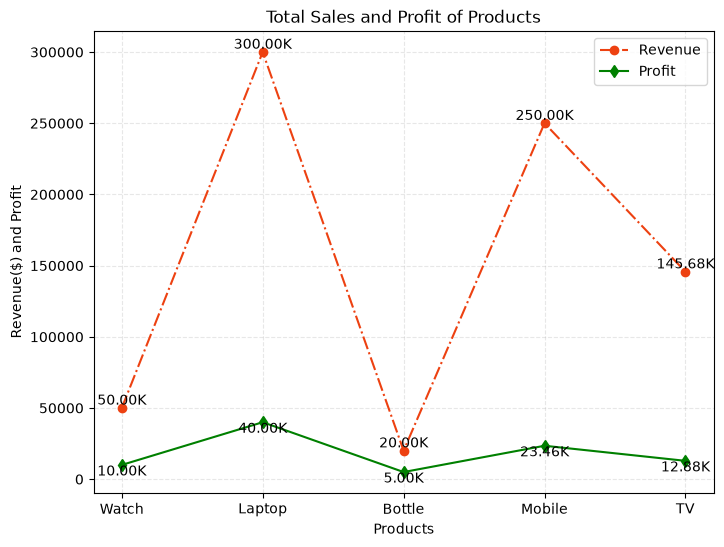

In [4]:
plt.figure(figsize=(8, 6)) # 600 x 400 px
plt.plot(product, revenue, marker='o', color='#ED4111', linestyle='-.', label='Revenue')
plt.plot(product, profit, marker='d', color='green', label='Profit')
plt.xlabel('Products')
plt.ylabel('Revenue($) and Profit')
plt.title('Total Sales and Profit of Products')
plt.legend()

for idx, val in enumerate(revenue):
    plt.text(idx, val, priceConverter(val), ha='center', va='bottom')
    
for idx, val in enumerate(profit):
    plt.text(idx, val, priceConverter(val), ha='center', va='top')

plt.grid(linestyle='dashed', alpha=0.3)
plt.savefig('product_revenue_profit.png')
plt.show()

## Bar Plot

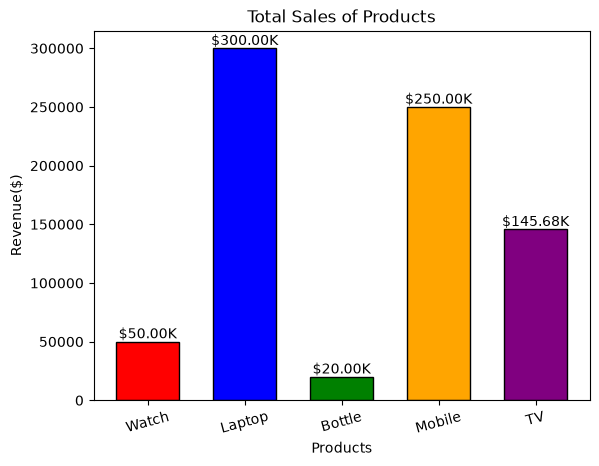

In [5]:
colors = ['red', 'blue', 'green', 'orange', 'purple']
plt.bar(product, revenue, color=colors, edgecolor='black', width=0.65)
plt.xlabel('Products')
plt.ylabel('Revenue($)')
plt.title('Total Sales of Products')
plt.xticks(rotation=15)

for idx, val in enumerate(revenue):
    plt.text(idx, val, f'${priceConverter(val)}', ha='center', va='bottom')

plt.show()

## Scatter Plot

In [6]:
temp = pd.read_csv('Dataset/temperature.csv')
temp.head(2)

,Temperature (°C),Humidity (%)
0,23.745401,57.186649
1,29.507143,66.765614


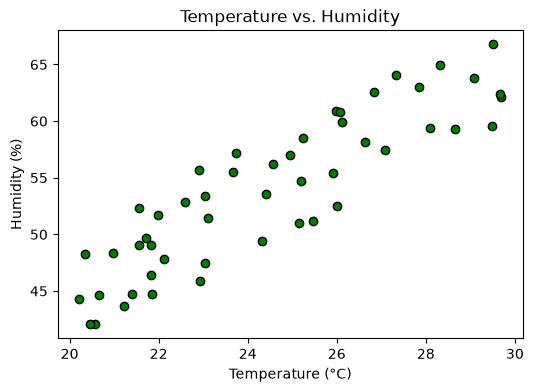

In [7]:
plt.figure(figsize=(6, 4))
plt.scatter(temp['Temperature (°C)'], temp['Humidity (%)'], color='green', edgecolor='black')
plt.xlabel('Temperature (°C)')
plt.ylabel('Humidity (%)')
plt.title('Temperature vs. Humidity')
plt.show()

## HR Data

In [8]:
df = pd.read_csv('cleaned_data.csv')
df.head(2)

,Employee_Name,EmpID,MarriedID,MaritalStatusID,GenderID,EmpStatusID,DeptID,PerfScoreID,FromDiversityJobFairID,Salary,...,DaysLateLast30,Absences,hire_year,hire_month,hire_day,month_name,day_name,salary_label,Sal1,Sal2
0,Adinolfi Wilson K,10026,0,0,1,1,5,4,0,62506,...,0,1,2011,7,5,July,Tuesday,Average Salary,Average,Salary
1,Akinkuolie Sarah,10196,1,1,0,5,5,3,0,64955,...,0,3,2011,7,5,July,Tuesday,Average Salary,Average,Salary


## Pie Chart

In [9]:
emp_perf = df.groupby('PerformanceScore')['EmpID'].count().reset_index().rename(
    columns = {'PerformanceScore': 'Performance Score', 'EmpID': 'Total Employees'}
)
emp_perf

,Performance Score,Total Employees
0,Exceeds,32
1,Fully Meets,221
2,Needs Improvement,16
3,PIP,13


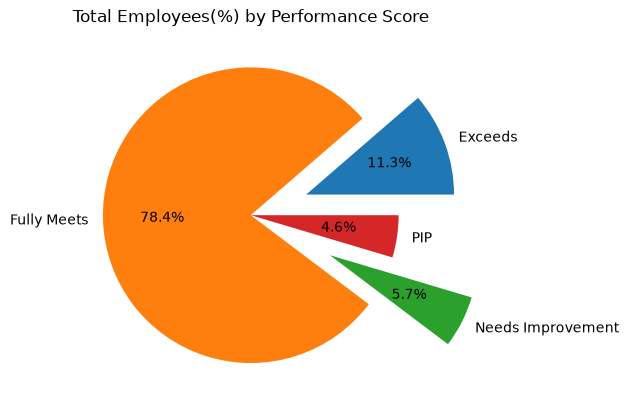

In [10]:
plt.pie(
    emp_perf['Total Employees'],
    labels = emp_perf['Performance Score'],
    autopct = '%1.1f%%',
    explode = (0.4, 0, 0.6, 0),
    # width edge properties
    wedgeprops={'width': 1}
)
plt.title('Total Employees(%) by Performance Score')
plt.show()

## Donut Chart

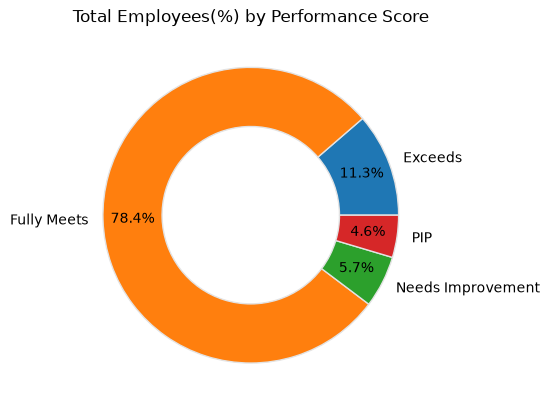

In [11]:
plt.pie(
    emp_perf['Total Employees'],
    labels = emp_perf['Performance Score'],
    autopct = '%1.1f%%',
    wedgeprops={'width': 0.4, 'edgecolor': '#e3e3e3'},
    pctdistance=0.8,
    # explode = (0.4, 0, 0.6, 0)
)
plt.title('Total Employees(%) by Performance Score')
plt.show()

## Column Chart

In [12]:
emp_gender_perf = df.groupby(['PerformanceScore', 'Gender'])['EmpID'].count().reset_index().rename(
    columns = {'PerformanceScore': 'Performance Score', 'EmpID': 'Total Employees'}
)
# emp_gender_perf

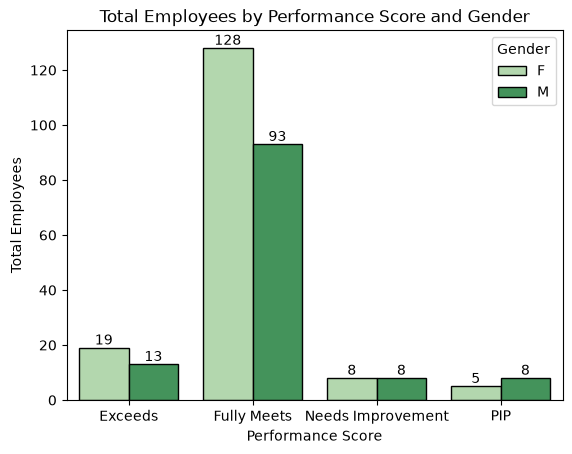

In [13]:
ax = sns.barplot(
    data=emp_gender_perf,
    x='Performance Score',
    y='Total Employees',
    hue='Gender',
    errorbar=None,
    palette='Greens',
    edgecolor='black'
)
plt.title('Total Employees by Performance Score and Gender')
for container in ax.containers:
    plt.bar_label(container)

plt.show()

## Stacked Chart

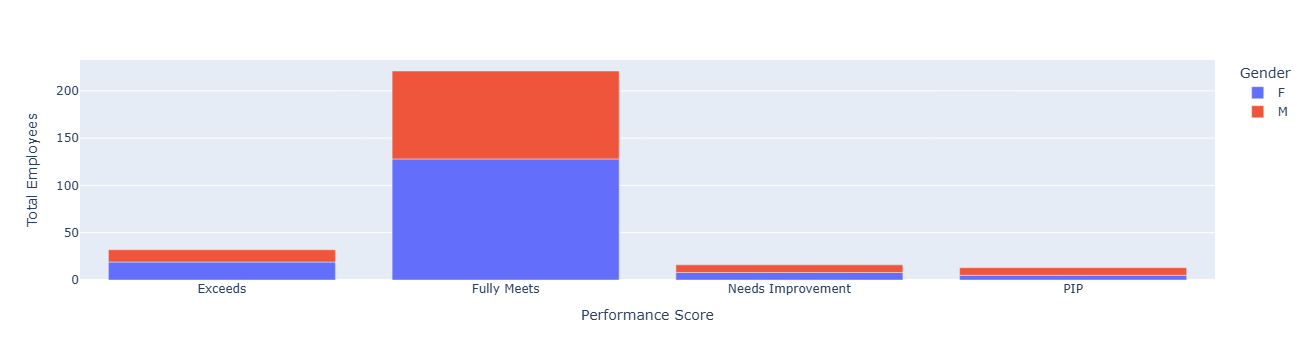

In [14]:
px.bar(
    emp_gender_perf,
    x='Performance Score',
    y='Total Employees',
    color='Gender',
    # barmode='group' # used to create column chart
)

## Histograms

In [15]:
hr = pd.read_csv('Dataset/HR_Dataset Refresh.csv')

In [16]:
hr_salary = hr[hr['Salary'] < 87000]
# hr_salary

In [17]:
unfiltered_salary = hr['Salary'].skew()
filtered_hr_salary = hr_salary['Salary'].skew()

print(f'Unfiltered Salary: {unfiltered_salary}')
print(f'Filtered Salary: {filtered_hr_salary}')

Unfiltered Salary: 7.9687080321322
Filtered Salary: 0.38894271311424977


In [18]:
mean_salary = hr_salary['Salary'].mean()
median_salary = hr_salary['Salary'].median()

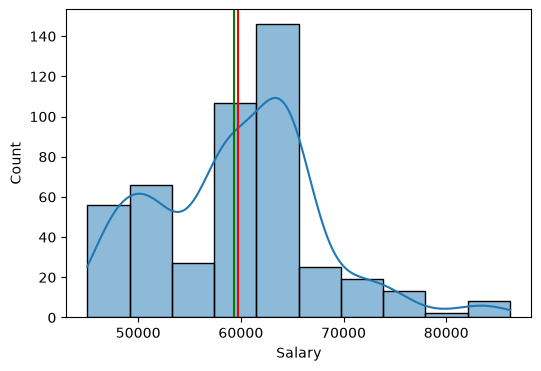

In [19]:
# KDE -> Kernel Density Estimator
plt.figure(figsize=(6, 4))
sns.histplot(hr_salary['Salary'], bins=10, kde=True)
# axvline -> axis vertical line
plt.axvline(mean_salary, color='red')
plt.axvline(median_salary, color='green')
plt.show()

## Box Plot

<Axes: ylabel='Salary'>

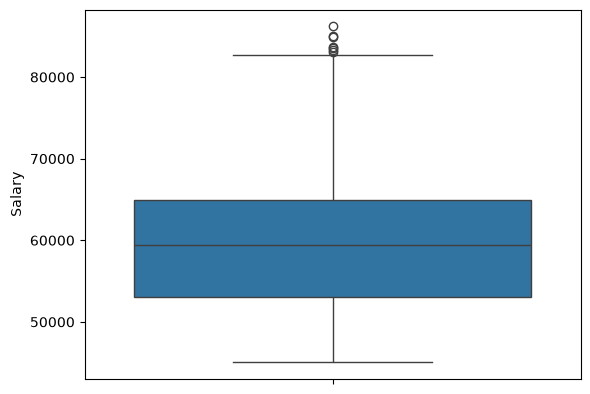

In [20]:
sns.boxplot(hr_salary['Salary'])

<Axes: >

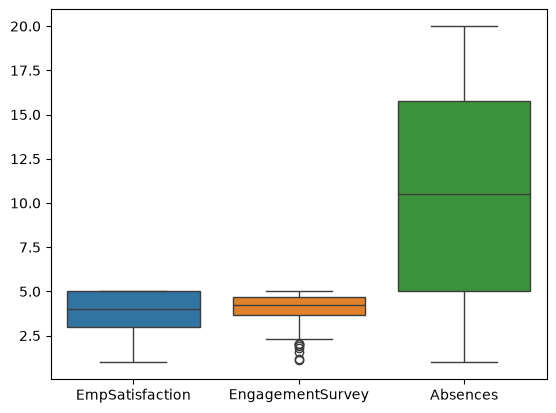

In [21]:
sns.boxplot(df[['EmpSatisfaction', 'EngagementSurvey', 'Absences']])

## Violin Plot

In [22]:
fig = px.violin(
    hr_salary,
    y=['Salary'],
    box=True,
    points='all'
)
# fig.close()

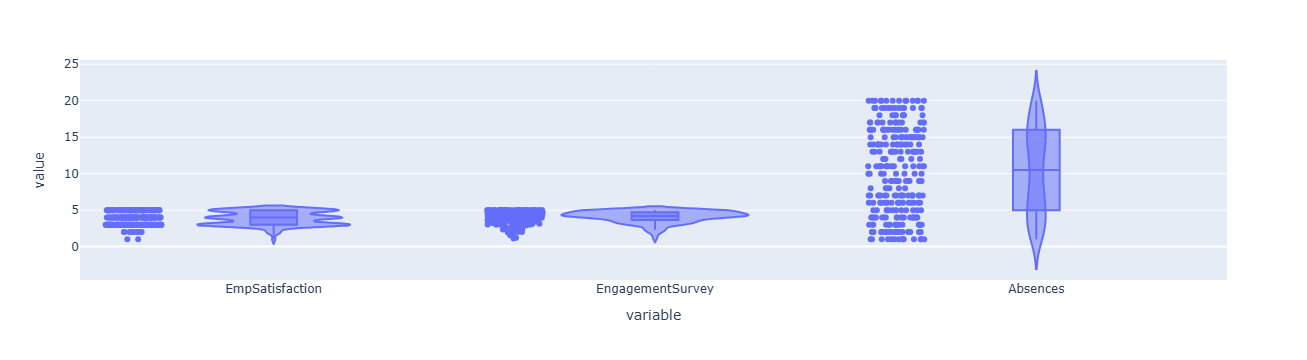

In [23]:
fig = px.violin(
    df,
    y=['EmpSatisfaction', 'EngagementSurvey', 'Absences'],
    box=True,
    points='all'
)
fig.show()

## Correlation Heatmap

In [24]:
filtered_data = df.drop(columns = ['Employee_Name', 'EmpID', 'MarriedID', 'MaritalStatusID', 'GenderID',
       'EmpStatusID', 'DeptID', 'FromDiversityJobFairID', 'PositionID', 'Position', 'State', 'Zip', 'DOB',
       'Gender', 'MaritalDesc', 'CitizenDesc', 'HispanicLatino', 'RaceDesc',
       'DateofHire', 'DateofTermination', 'TermReason', 'EmploymentStatus',
       'Department', 'ManagerName', 'ManagerID', 'RecruitmentSource',
       'PerformanceScore', 'LastPerformanceReview_Date', 'hire_year', 'hire_month', 'hire_day', 'month_name',
       'day_name', 'salary_label', 'Sal1', 'Sal2'])

In [25]:
filtered_data.columns

Index(['PerfScoreID', 'Salary', 'Termd', 'EngagementSurvey', 'EmpSatisfaction',
       'SpecialProjectsCount', 'DaysLateLast30', 'Absences'],
      dtype='str')

In [26]:
corr_data = filtered_data.corr(method='pearson')

<Axes: >

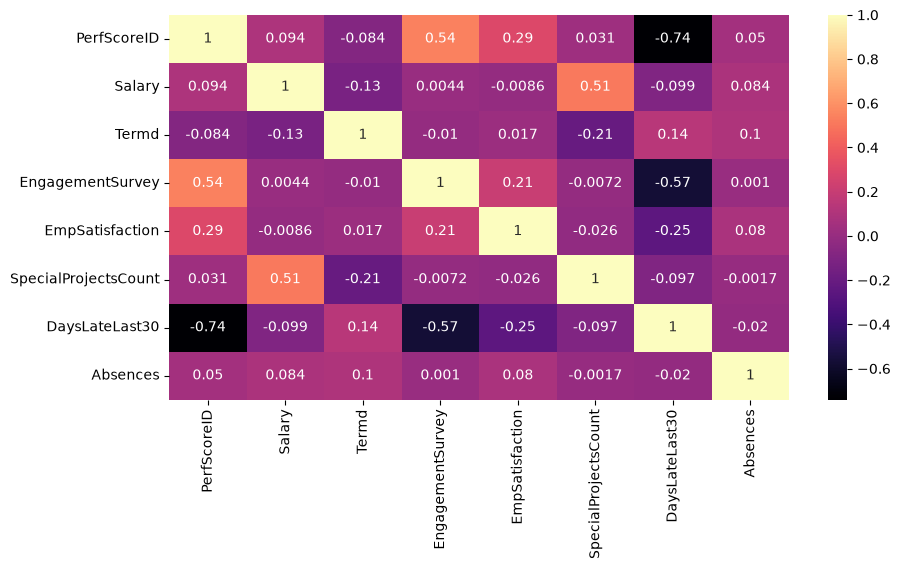

In [27]:
plt.figure(figsize=(10, 5))
sns.heatmap(corr_data, annot=True, cmap='magma')

## Tree Map

In [28]:
data = df.groupby(['Department', 'Position', 'Gender'])['EmpID'].count().reset_index().rename(
    columns = {'EmpID': 'Total Employees'}
)

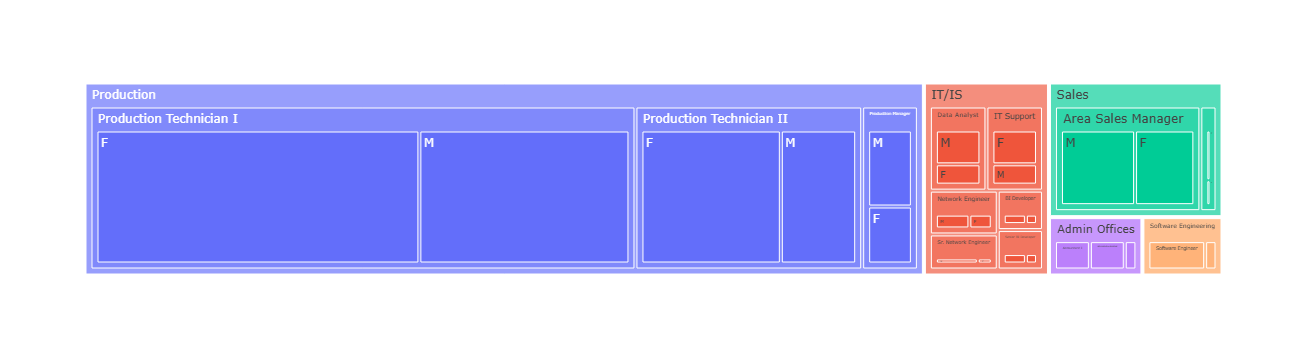

In [29]:
fig = px.treemap(
    data,
    path=['Department', 'Position', 'Gender'],
    values='Total Employees'
)
fig.show()

## Subplots

In [33]:
dep_details = df.groupby('Department').agg(
    Total_Employees = ('EmpID', 'count'),
    Total_Salary = ('Salary', 'sum'),
    Total_Projects = ('SpecialProjectsCount', 'sum'),
    Total_Absences = ('Absences', 'sum')
).reset_index()
dep_details.columns = dep_details.columns.str.replace('_', ' ', regex=False)
dep_details

,Department,Total Employees,Total Salary,Total Projects,Total Absences
0,Admin Offices,7,440409,28,71
1,IT/IS,31,2430931,183,342
2,Production,208,12359791,4,2105
3,Sales,30,1960899,0,339
4,Software Engineering,6,529314,26,33


In [84]:
def showValue(data, ax, ho_al='center', va_al='bottom'):
    for idx, val in enumerate(data):
        ax.text(idx,val, priceConverter(val), ha=ho_al, va=va_al)

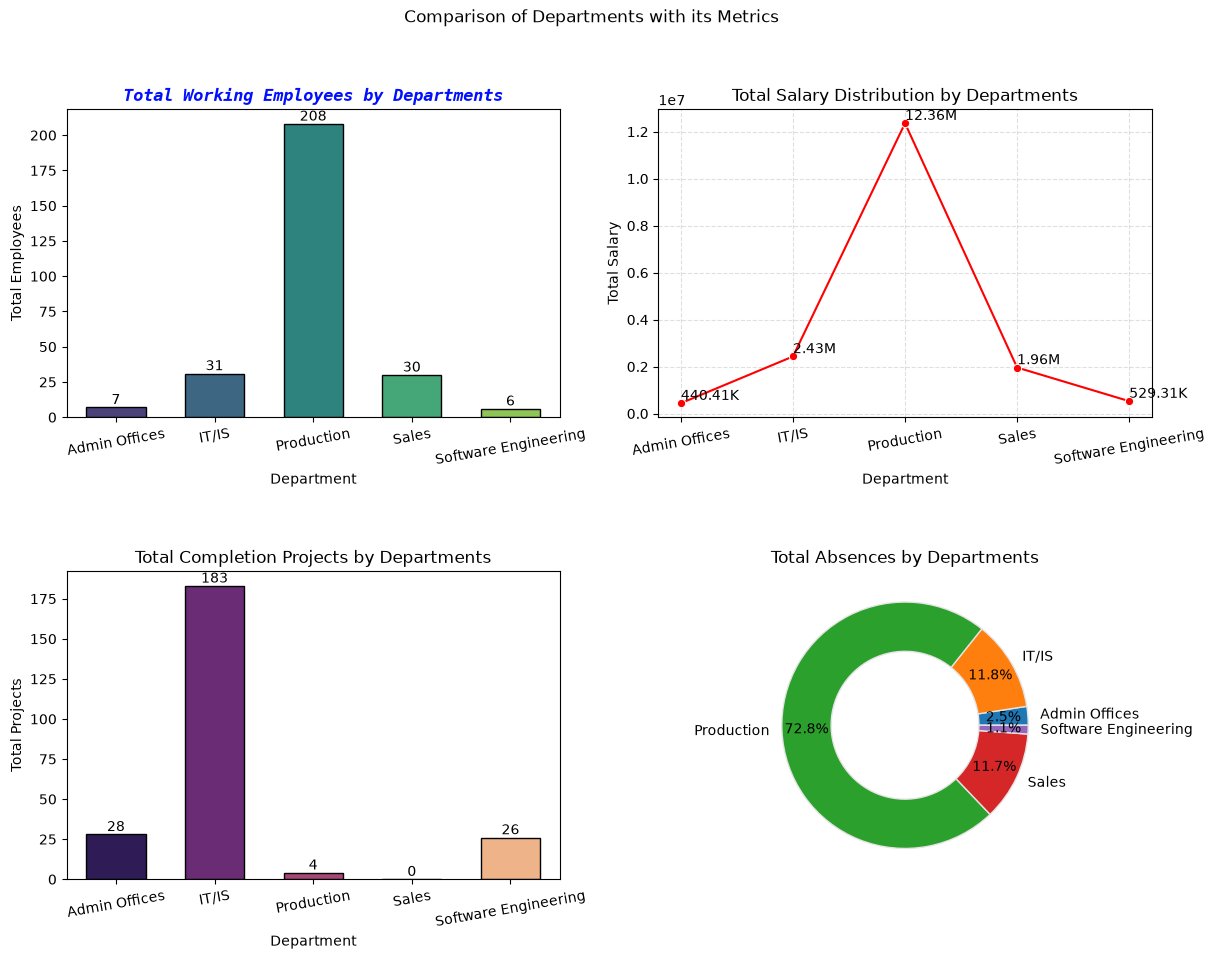

In [97]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
# plt.subplots_adjust(hspace=0.5, wspace=0.5)
plt.subplots_adjust(hspace=0.5)
plt.suptitle('Comparison of Departments with its Metrics')

xAxis = dep_details['Department']

ax1 = axes[0, 0]
sns.barplot(x=xAxis, y=dep_details['Total Employees'], ax=ax1, edgecolor='black', hue=xAxis, palette='viridis', width=0.6)
ax1.set_title('Total Working Employees by Departments', fontsize='large', fontweight='bold', fontfamily='monospace', color='#000fff', fontstyle='oblique')
ax1.tick_params(axis='x', rotation=10)
showValue(dep_details['Total Employees'], ax1)

ax2 = axes[0, 1]
sns.lineplot(x=xAxis, y=dep_details['Total Salary'], ax=ax2, marker='o', color='red')
ax2.set_title('Total Salary Distribution by Departments')
ax2.tick_params(axis='x', rotation=10)
ax2.grid(linestyle='dashed', alpha=0.4)
showValue(dep_details['Total Salary'], ax2, ho_al='left')

ax3 = axes[1, 0]
sns.barplot(x=xAxis, y=dep_details['Total Projects'], ax=ax3,  edgecolor='black', hue=xAxis, palette='magma', width=0.6)
ax3.set_title('Total Completion Projects by Departments')
ax3.tick_params(axis='x', rotation=10)
showValue(dep_details['Total Projects'], ax3)

ax4 = axes[1, 1]
ax4.pie(
    dep_details['Total Absences'],
    labels=xAxis,
    autopct='%1.1f%%',
    wedgeprops={'width': 0.4, 'edgecolor': '#e4e4e4'},
    pctdistance=0.8
)
ax4.set_title('Total Absences by Departments')

plt.show()